# **imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
import xgboost as xgb
from sklearn.metrics import root_mean_squared_error

# **importing the data**

In [ ]:
import kagglehub

path = kagglehub.dataset_download("arnabchaki/laptop-price-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'laptop-price-prediction' dataset.
Path to dataset files: /kaggle/input/laptop-price-prediction


In [3]:
import os

files = os.listdir(path)
csv_files = [f for f in files if f.endswith('.csv')]
file_name = csv_files[0]
file_path = os.path.join(path, file_name)
df = pd.read_csv(file_path)



# ***EDA* and cleaning the data**


In [4]:
df.head(10)


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37kg,11912523.48
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,7993374.48
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86kg,5112900.00
3,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83kg,22563005.40
4,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37kg,16037611.20
5,Acer,Aspire 3,Notebook,"15.6""",1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows,10,2.1kg,3556800.00
6,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16GB,256GB Flash Storage,Intel Iris Pro Graphics,Mac OS,X,2.04kg,19028613.24
7,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,256GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,10303160.40
8,Asus,ZenBook UX430UN,Ultrabook,"14.0""",Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows,10,1.3kg,13293540.00
9,Acer,Swift 3,Ultrabook,"14.0""",IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows,10,1.6kg,6846840.00


In [5]:
df.columns = df.columns.str.replace(' ', '_')
df.columns = df.columns.str.lower()
df = df.rename(columns={'_storage': 'storage'})
print(round(df.describe()))
print(df.info())


            price
count       977.0
mean   10018995.0
std     6306430.0
min     1706375.0
25%     5326308.0
50%     8527428.0
75%    13115700.0
max    54232308.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 977 entries, 0 to 976
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   manufacturer              977 non-null    object 
 1   model_name                977 non-null    object 
 2   category                  977 non-null    object 
 3   screen_size               977 non-null    object 
 4   screen                    977 non-null    object 
 5   cpu                       977 non-null    object 
 6   ram                       977 non-null    object 
 7   storage                   977 non-null    object 
 8   gpu                       977 non-null    object 
 9   operating_system          977 non-null    object 
 10  operating_system_version  841 non-null    object 
 11  weight       

In [6]:
print(df.isnull().sum())
df['operating_system_version'] = df['operating_system_version'].fillna("Unknown")
(df['operating_system_version'] == 'Unknown').sum()


np.int64(136)

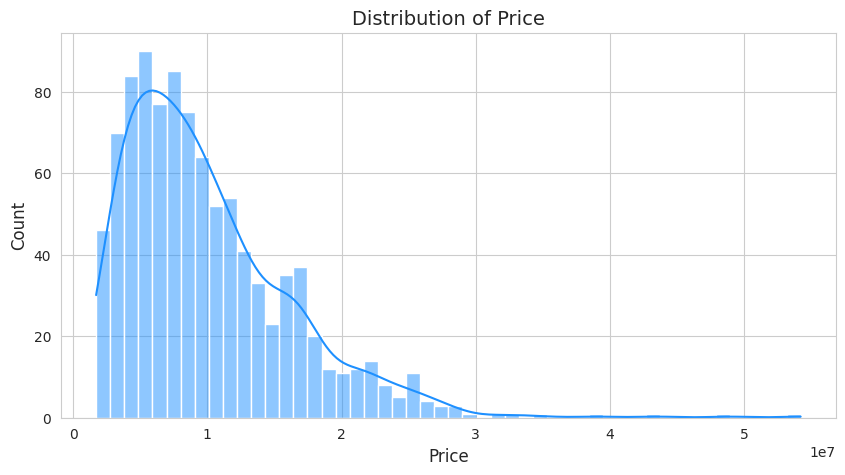

In [7]:
sns.set_style('whitegrid')

plt.figure(figsize=(10, 5))

sns.histplot(df['price'], bins=50, kde=True, color='dodgerblue')

plt.title('Distribution of Price', fontsize=14)
plt.xlabel('Price', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()
#so we have long tail, that cause nois to our model

In [8]:
# we take log of price instead, this should remove the long tail
df['log_price'] = np.log1p(df['price'])
del df['price']

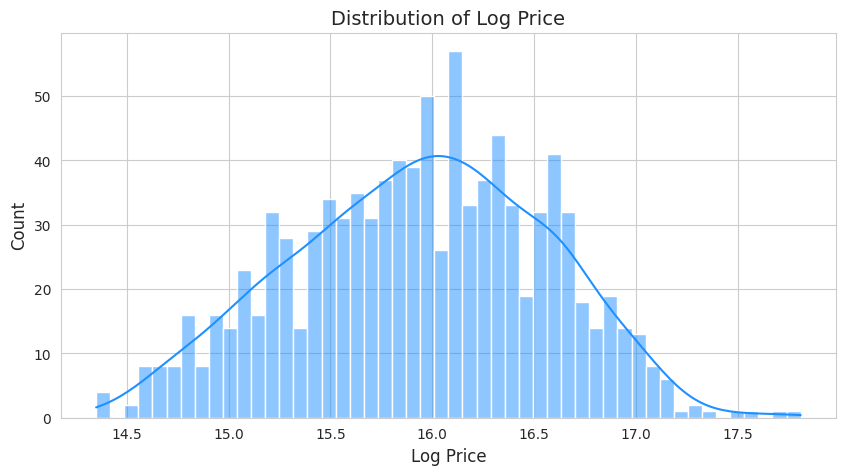

In [9]:
sns.set_style('whitegrid')

plt.figure(figsize=(10, 5))

sns.histplot(df['log_price'], bins=50, kde=True, color='dodgerblue')

plt.title('Distribution of Log Price', fontsize=14)
plt.xlabel('Log Price', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()
#no long tail after log

In [10]:
# Extract numeric values
if 'ram' in df.columns and df['ram'].dtype == 'object':
    df['ram'] = df['ram'].str.extract(r'([\d\.]+)').astype(float)

if 'weight' in df.columns and df['weight'].dtype == 'object':
    df['weight'] = df['weight'].str.extract(r'([\d\.]+)').astype(float)

if 'screen_size' in df.columns and df['screen_size'].dtype == 'object':
    df['screen_size'] = df['screen_size'].str.extract(r'([\d\.]+)').astype(float)

# Now, compute correlation matrix
correlation_matrix = df.corr(numeric_only=True)
display(correlation_matrix)
#we see that ram have high corr with log_price, so its so good to help our model to learn better

,screen_size,ram,weight,log_price
screen_size,1.000000,0.232315,0.822261,0.053449
ram,0.232315,1.000000,0.390161,0.708061
weight,0.822261,0.390161,1.000000,0.163321
log_price,0.053449,0.708061,0.163321,1.000000


In [11]:
df.dtypes

,0
manufacturer,object
model_name,object
category,object
screen_size,float64
screen,object
cpu,object
ram,float64
storage,object
gpu,object
operating_system,object


In [12]:
cat = ['manufacturer','model_name','category','screen', 'cpu', 'storage', 'gpu', 'operating_system', 'operating_system_version']

In [13]:
print(df[cat].nunique())
#model_name is so noisy so we will delete it
del df['model_name']

manufacturer                 19
model_name                  488
category                      6
screen                       38
cpu                         106
storage                      36
gpu                          98
operating_system              7
operating_system_version      5
dtype: int64


# **splitting the data, training the models and tuning their hyperparameters**

In [ ]:
# Split the dataset into training, validation, and test sets
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['log_price'].values
y_val = df_val['log_price'].values
y_test = df_test['log_price'].values

del df_train['log_price']
del df_val['log_price']
del df_test['log_price']


In [ ]:
#encode categorical features using DictVectorizer
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)


In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr.predict(X_val)
y_pred_lr = lr.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred_lr)
rmse

0.23003473354050946


In [ ]:
#ridge regression hyperparameter tuning
alphas = [0.001, 0.01, 0.1, 1.0, 10, 100, 1000]
s = []
for it in range(5, 501, 10):
  for a in alphas:

    ridge = Ridge(alpha=a, random_state=1,max_iter=it)
    ridge.fit(X_train, y_train)

    y_pred_ridge = ridge.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred_ridge)

    print(f'iter: {it}   Alpha: {a:6.3f} --> Log RMSE: {rmse:.4f}')
    s.append((it, a, rmse))
    df_s = pd.DataFrame(s, columns=['num_iter', 'alpha', 'rmse'])
#iter: 5   Alpha:  1.000 --> Log RMSE: 0.2196 the best

iter: 5   Alpha:  0.001 --> Log RMSE: 0.2299
iter: 5   Alpha:  0.010 --> Log RMSE: 0.2288
iter: 5   Alpha:  0.100 --> Log RMSE: 0.2231
iter: 5   Alpha:  1.000 --> Log RMSE: 0.2196
iter: 5   Alpha: 10.000 --> Log RMSE: 0.2328
iter: 5   Alpha: 100.000 --> Log RMSE: 0.2869
iter: 5   Alpha: 1000.000 --> Log RMSE: 0.3765
iter: 15   Alpha:  0.001 --> Log RMSE: 0.2299
iter: 15   Alpha:  0.010 --> Log RMSE: 0.2288
iter: 15   Alpha:  0.100 --> Log RMSE: 0.2231
iter: 15   Alpha:  1.000 --> Log RMSE: 0.2196
iter: 15   Alpha: 10.000 --> Log RMSE: 0.2328
iter: 15   Alpha: 100.000 --> Log RMSE: 0.2869
iter: 15   Alpha: 1000.000 --> Log RMSE: 0.3765
iter: 25   Alpha:  0.001 --> Log RMSE: 0.2299
iter: 25   Alpha:  0.010 --> Log RMSE: 0.2288
iter: 25   Alpha:  0.100 --> Log RMSE: 0.2231
iter: 25   Alpha:  1.000 --> Log RMSE: 0.2196
iter: 25   Alpha: 10.000 --> Log RMSE: 0.2328
iter: 25   Alpha: 100.000 --> Log RMSE: 0.2869
iter: 25   Alpha: 1000.000 --> Log RMSE: 0.3765
iter: 35   Alpha:  0.001 --> Log

In [18]:
df_s.sort_values(by='rmse', ascending=True).head(50)

,num_iter,alpha,rmse
3,5,1.0,0.219564
346,495,1.0,0.219564
31,45,1.0,0.219564
38,55,1.0,0.219564
318,455,1.0,0.219564
325,465,1.0,0.219564
52,75,1.0,0.219564
45,65,1.0,0.219564
66,95,1.0,0.219564
59,85,1.0,0.219564


In [ ]:
#best ridge model
ridge = Ridge(alpha=1, max_iter=5, random_state=1)
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred_ridge)
rmse

0.21956363026728784

In [ ]:
#rf prams tuning
scores = []

for n in range(5, 201, 10):
  for d in range(2, 20, 1):
    rf = RandomForestRegressor(
        n_estimators=n, max_depth=d, random_state=1, n_jobs=-1
    )
    rf.fit(X_train, y_train)

    y_pred_rf = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred_rf)

    scores.append((n, d, rmse))

columns = ['n_estimators', 'max_depth', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)

In [21]:
df_scores.sort_values(by='rmse', ascending=True).head(50)

,n_estimators,max_depth,rmse
11,5,13,0.219931
47,25,13,0.221457
68,35,16,0.221606
66,35,14,0.221739
356,195,16,0.221973
359,195,19,0.221995
67,35,15,0.222060
338,185,16,0.222060
70,35,18,0.222091
65,35,13,0.222102


In [ ]:
#best rf parameters
rf = RandomForestRegressor(
        n_estimators=5, max_depth=13, random_state=1, n_jobs=-1
    )
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred_rf)
rmse

0.21993064900608927

In [ ]:
#XGBoost hyperparameter tuning
scores = {}

dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
watchlist = [(dtrain, 'train'), (dval, 'val')]

for e in [0.05, 0.1, 0.3]:
  for d in [3, 5, 6, 10]:
    for m in [1, 4]:
      key = f'eta={e}, d={d}, m={m}'

      xgb_prams = {
          'eta': e,
          'max_depth': d,
          'min_child_weight': m,
          'objective': 'reg:squarederror',
          'eval_metric': 'rmse',
          'nthread': 8,
          'seed': 1,
          'verbosity': 0,
      }

      evals_result = {}

      model = xgb.train(
          xgb_prams,
          dtrain,
          num_boost_round=500,
          evals=watchlist,
          evals_result=evals_result,
          verbose_eval=False,
      )

      val_rmse = evals_result['val']['rmse']
      num_iter = list(range(len(val_rmse)))

      scores[key] = pd.DataFrame({'num_iter': num_iter, 'val_rmse': val_rmse})

In [ ]:
#taking the best prams from the previous tuning
summary_data = []

for key, df_score in scores.items():
  best_rmse = df_score['val_rmse'].min()
  best_iter = df_score['val_rmse'].idxmin()

  summary_data.append(
      {'config': key, 'best_rmse': best_rmse, 'best_iter': best_iter}
  )

df_summary = pd.DataFrame(summary_data)
df_summary = df_summary.sort_values(by='best_rmse').reset_index(drop=True)


print(df_summary.head(10))

               config  best_rmse  best_iter
0   eta=0.3, d=3, m=1   0.198938        486
1   eta=0.1, d=3, m=1   0.200904        499
2   eta=0.1, d=5, m=1   0.202319        483
3   eta=0.3, d=5, m=1   0.203611        162
4  eta=0.05, d=6, m=1   0.205141        499
5  eta=0.05, d=5, m=1   0.205448        495
6   eta=0.1, d=6, m=1   0.206062        283
7   eta=0.3, d=3, m=4   0.208036        358
8   eta=0.1, d=3, m=4   0.209345        499
9   eta=0.3, d=6, m=1   0.209936         69


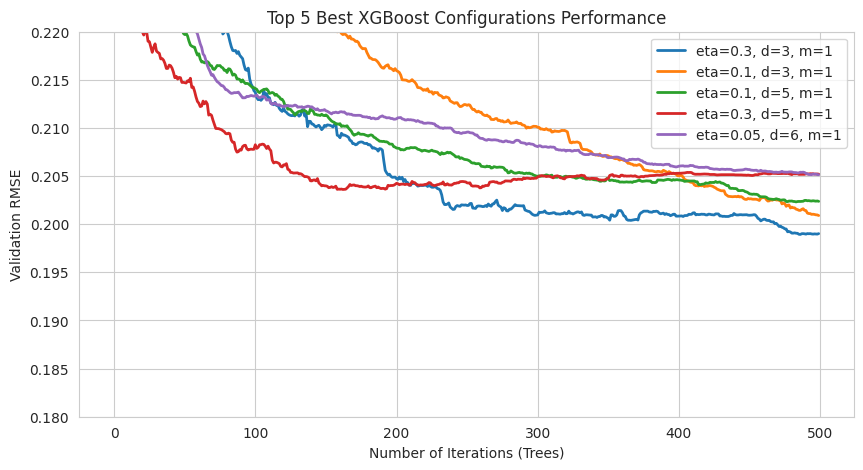

In [ ]:
#plotting the top 5 best configurations
plt.figure(figsize=(10, 5))

top_configs = df_summary['config'].head(5).tolist()

for config in top_configs:
  df_score = scores[config]
  plt.plot(
      df_score['num_iter'],
      df_score['val_rmse'],
      label=config,
      linewidth=2,
  )

plt.ylim(0.18, 0.22)
plt.xlabel('Number of Iterations (Trees)')
plt.ylabel('Validation RMSE')
plt.title('Top 5 Best XGBoost Configurations Performance')
plt.legend()
plt.grid(True)
plt.show()

#i will use 'config  best_rmse  best_iter
# eta=0.3, d=3, m=1  0.198938       486'

In [ ]:
#best xgb_prams training
xgb_prams = {
          'eta': 0.3,
          'max_depth': 3,
          'min_child_weight': 1,
          'objective': 'reg:squarederror',
          'eval_metric': 'rmse',
          'nthread': 8,
          'seed': 1,
          'verbosity': 0,
      }

evals_result = {}

model = xgb.train(
    xgb_prams,
    dtrain,
    num_boost_round=486,
    evals=watchlist,
    verbose_eval=5,
)

[0]	train-rmse:0.49772	val-rmse:0.48114
[5]	train-rmse:0.28933	val-rmse:0.27758
[10]	train-rmse:0.24308	val-rmse:0.25153
[15]	train-rmse:0.22282	val-rmse:0.24480
[20]	train-rmse:0.21052	val-rmse:0.23708
[25]	train-rmse:0.19965	val-rmse:0.23421
[30]	train-rmse:0.19241	val-rmse:0.23200
[35]	train-rmse:0.18714	val-rmse:0.23085
[40]	train-rmse:0.18146	val-rmse:0.22998
[45]	train-rmse:0.17687	val-rmse:0.22640
[50]	train-rmse:0.17131	val-rmse:0.22483
[55]	train-rmse:0.16667	val-rmse:0.22602
[60]	train-rmse:0.16178	val-rmse:0.22211
[65]	train-rmse:0.15837	val-rmse:0.22140
[70]	train-rmse:0.15584	val-rmse:0.22015
[75]	train-rmse:0.15285	val-rmse:0.22058
[80]	train-rmse:0.14668	val-rmse:0.22004
[85]	train-rmse:0.14299	val-rmse:0.21802
[90]	train-rmse:0.14018	val-rmse:0.21738
[95]	train-rmse:0.13816	val-rmse:0.21622
[100]	train-rmse:0.13217	val-rmse:0.21371
[105]	train-rmse:0.13071	val-rmse:0.21304
[110]	train-rmse:0.12934	val-rmse:0.21314
[115]	train-rmse:0.12774	val-rmse:0.21234
[120]	train-rm

# final training and choosing the **model**

In [ ]:
#final model training and evaluation on the test set
y_full_train = df_full_train['log_price'].values
del df_full_train['log_price']

full_train_dict = df_full_train.to_dict(orient='records')
X_full_train = dv.fit_transform(full_train_dict)

test_dict = df_test.to_dict(orient='records')
X_test = dv.transform(test_dict)

dfull_train = xgb.DMatrix(X_full_train, label=y_full_train)
dtest = xgb.DMatrix(X_test, label=y_test)


In [ ]:
#XGBoost
final_params = {
    'eta': 0.3,
    'max_depth': 3,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'nthread': 8,
    'seed': 1,
}

final_model = xgb.train(final_params, dfull_train, num_boost_round=486)

y_pred_test = final_model.predict(dtest)
final_test_rmse = root_mean_squared_error(y_test, y_pred_test)

print(f'Final Test Log RMSE: {final_test_rmse:.5f}')

Final Test Log RMSE: 0.22417


In [ ]:
#linear regression
lr = LinearRegression()
lr.fit(X_full_train, y_full_train)
y_pred_lr = lr.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred_lr)
print(rmse)

0.23311852959169907


In [ ]:
#Random Forest Regressor
rf = RandomForestRegressor(n_estimators=5, max_depth=13, random_state=1, n_jobs=-1)
rf.fit(X_full_train, y_full_train)

y_pred_rf = rf.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred_rf)
rmse

0.28153153933161523

In [ ]:
#Ridge Regression
ridge = Ridge(alpha=1, max_iter=5, random_state=1)
ridge.fit(X_full_train, y_full_train)

y_pred_ridge = ridge.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred_ridge)
rmse

0.22972185828973682